# 사출성형 불량 예측 — 쉽게 풀어 쓴 설명 노트북

이 노트북은 우리 팀 베이스라인이 **무엇을, 왜, 어떻게** 하는지 한 단계씩 보여 줍니다.

- 코드는 모두 `src/` 폴더에 있는 함수를 **불러서 쓰기만** 합니다. (새로운 계산 방법을 여기서 만들지 않아요)
- 여기서는 빨리 보려고 **작게**(반복 2번, 모델 1~2개) 돌립니다. 모든 모델·반복을 다 돌린 **진짜 결과**는
  `python run_all.py` 를 실행하면 생기는 `outputs/report.md` 에 있어요.
- 어려운 말이 나오면 맨 아래 **용어 사전**을 보세요.

## 0. 준비하기

필요한 도구(함수)들을 불러오고, 설정 파일(`config.json`)을 읽습니다.
설정 파일은 **요리 레시피**와 같아요. 몇 번 섞을지(반복 수), 어떤 재료를 뺄지(금지 변수) 같은 약속이 다 적혀 있어서,
누가 실행해도 같은 결과가 나옵니다.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import cv, experiments, features
from src.audit import defect_sequence, row_level_ceiling
from src.data import assign_shots, load_all, shot_table
from src.evaluate import recall_at_budget, shot_types

pd.set_option("display.width", 160)
cfg = json.loads((ROOT / "config.json").read_text(encoding="utf-8"))
data_dir = ROOT / cfg["data_dir"]
SYNTHETIC = not (data_dir / cfg["products"]["cn7"]["labeled"]).exists()
if SYNTHETIC:  # 대회 데이터가 없으면 모양만 같은 가짜 데이터로 (숫자는 의미 없음)
    from src.synthetic import generate
    data_dir = generate(ROOT / "data" / "synthetic")
FIG = ROOT / cfg["output_dir"] / ("synthetic/figures" if SYNTHETIC else "figures")
print("가짜 데이터로 실행 중 (숫자는 의미 없음)" if SYNTHETIC else "대회 데이터로 실행 중")

대회 데이터로 실행 중


## 1. 데이터 불러오기 — 공장의 '일기장'

사출성형기는 플라스틱을 녹여 틀(금형)에 쏘아 넣는 기계예요. 한 번 쏠 때마다(이걸 **shot** 이라고 해요)
온도, 압력, 시간 같은 숫자 24개가 기록됩니다
(그중 1개는 labeled 데이터에서 늘 같은 값이라 빼고 23개를 씁니다). 우리 데이터는 이 **공장 일기장**이고, 각 줄에는 그 제품이
**양품(0)인지 불량(1)인지** 정답이 붙어 있어요.

제품은 두 종류(CN7, RG3)이고, 숫자들은 이미 **표준화**(평균 0, 흩어진 정도 1로 맞춤)되어 있어서 원래 단위(℃, bar)는 알 수 없어요.

In [2]:
data = load_all(cfg, data_dir)
feats = data["feature_cols"]
for p, lab in data["labeled"].items():
    print(f"{p.upper()}: {len(lab):,}행, 불량 {int(lab.y.sum())}행 ({lab.y.mean():.2%}), 공정 변수 {len(feats)}개")
data["labeled"]["cn7"][["row_id", "y", *feats[:5]]].head()

CN7: 1,211행, 불량 17행 (1.40%), 공정 변수 24개
RG3: 1,182행, 불량 25행 (2.12%), 공정 변수 24개


,row_id,y,Injection_Time,Filling_Time,Plasticizing_Time,Cycle_Time,Clamp_Close_Time
0,0,0,1.679123,1.491397,-0.478017,0.361047,0.97858
1,1,0,2.080358,1.894372,-0.527100,1.886261,0.97858
2,2,0,2.080358,1.894372,-0.527100,1.886261,0.97858
3,3,0,1.679123,1.894372,-0.527100,1.377857,0.97858
4,4,0,1.679123,1.894372,-0.527100,1.377857,0.97858


## 2. 쌍둥이 찾기 — 한 번 쏘면 제품이 2개 나온다

금형에는 칸이 두 개(왼쪽 LH, 오른쪽 RH) 있어서, 한 번 쏘면 제품이 **쌍둥이처럼 2개** 나와요.
두 제품은 같은 순간에 만들어졌으니 기록된 숫자도 **완전히 똑같아요**.

그래서 숫자가 똑같은 두 줄을 찾아 **같은 shot 번호**를 붙입니다. 이게 아주 중요한 이유는 두 가지예요.

1. 쌍둥이 중 한 명만 불량인 경우가 많아요. 그런데 둘의 숫자가 똑같으니 **어떤 모델도 둘을 구분할 수 없어요.**
   그래서 '행 단위' 점수에는 넘을 수 없는 **천장(상한)** 이 생겨요.
2. 쌍둥이 한 명은 공부(학습)에, 다른 한 명은 시험(검증)에 들어가면 **답을 미리 본 셈**이 돼요. 그래서 꼭 같이 다녀야 해요.

In [3]:
rows = []
for p in data["labeled"]:
    lab = assign_shots(data["labeled"][p], feats, p)
    data["labeled"][p] = lab
    st = shot_table(lab)
    types = shot_types(lab).value_counts()
    ceil = row_level_ceiling(st)
    rows.append({"제품": p.upper(), "shot 수": len(st), "쌍둥이(2행) shot": int((st.n_rows == 2).sum()),
                 "둘 다 불량": int(types.get("process_wide", 0)), "한쪽만 불량": int(types.get("cavity_local", 0)),
                 "정밀도 천장": round(ceil["row_precision_ceiling"], 3), "F1 천장": round(ceil["row_f1_ceiling"], 3)})
pd.DataFrame(rows)

,제품,shot 수,쌍둥이(2행) shot,둘 다 불량,한쪽만 불량,정밀도 천장,F1 천장
0,CN7,606,605,3,11,0.607,0.756
1,RG3,591,591,0,25,0.500,0.667


## 3. 불량은 언제 생겼을까?

불량이 하루 종일 골고루 생겼는지, 어느 한 때에 몰렸는지 봅니다. 몰려 있다면 조심해야 해요.
**바로 옆에서 만든 제품끼리는 서로 닮았기** 때문에, 옆 제품을 보고 공부한 모델은 쉽게 맞힐 수 있거든요.
(아래 그림은 `run_all.py` 가 만든 그림이에요.)

CN7: shot 606개 중 불량 shot 은 24번째 ~ 60번째 사이 (전체의 6% 구간)
RG3: shot 591개 중 불량 shot 은 68번째 ~ 566번째 사이 (전체의 84% 구간)


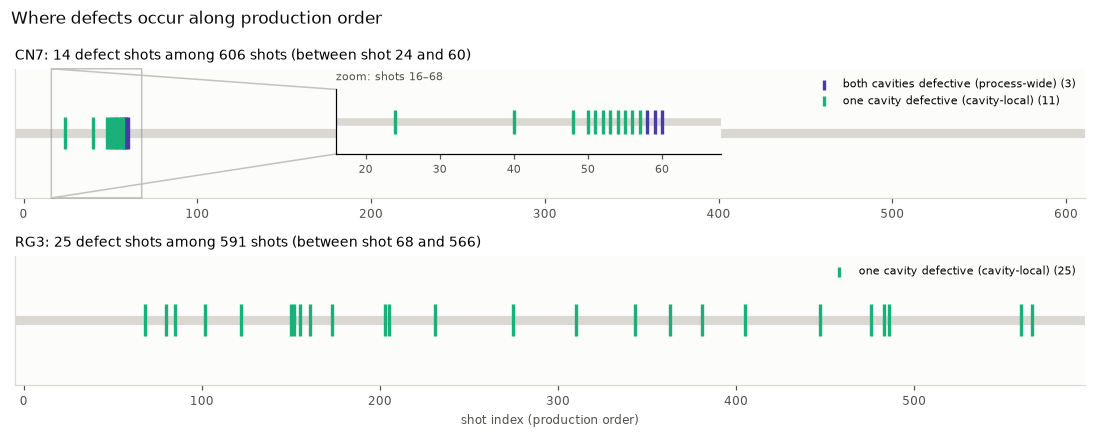

In [4]:
for p, lab in data["labeled"].items():
    d = defect_sequence(lab, shot_types(lab))
    print(f"{p.upper()}: shot {d['n_shots']}개 중 불량 shot 은 {d.get('first_defect_shot_idx')}번째 ~ "
          f"{d.get('last_defect_shot_idx')}번째 사이 (전체의 {d.get('defect_span_share', 0):.0%} 구간)")
if (FIG / "key1_defect_timeline.png").exists():
    display(Image(filename=str(FIG / "key1_defect_timeline.png")))

## 4. 시험 문제를 미리 보면 안 돼요 — 교차검증

모델이 잘하는지 알려면 **공부할 때 안 본 문제**로 시험을 봐야 해요. 데이터를 3묶음(fold)으로 나눠서,
2묶음으로 공부하고 1묶음으로 시험 보기를 돌아가며 3번 합니다. 이걸 **교차검증**이라고 해요.

우리는 나누는 방법을 두 가지로 해 봐요.

- **shot CV**: 쌍둥이는 꼭 같은 묶음에. 하지만 **바로 옆 shot** 은 다른 묶음에 들어갈 수 있어요 → 조금 **후한 점수**(낙관).
- **block CV**: 연속된 10개 shot 을 한 덩어리로 옮겨요. 옆 친구 답안도 못 보게 막는 셈이라 → **짠 점수**(비관).

진짜 실력은 이 두 점수 **사이 어딘가**에 있다고 보고, 둘을 함께 보고합니다.
아래 표는 팀원들도 같은 방법으로 나눌 수 있게 저장하는 **분할표**(`outputs/fold_id.csv`)의 앞부분이에요.

쌍둥이가 서로 다른 묶음에 들어간 경우가 있나요? 아니요 (안전)


,mold,row_id,shot_id,block_id,fold_shot_r0,fold_shot_r1,fold_block_r0,fold_block_r1
0,cn7,0,cn7_0,cn7_b0,0,0,1,1
1,cn7,1,cn7_1,cn7_b0,2,1,1,1
2,cn7,2,cn7_1,cn7_b0,2,1,1,1
3,cn7,3,cn7_2,cn7_b0,0,0,1,1
4,cn7,4,cn7_2,cn7_b0,0,0,1,1
5,cn7,5,cn7_3,cn7_b0,1,1,1,1


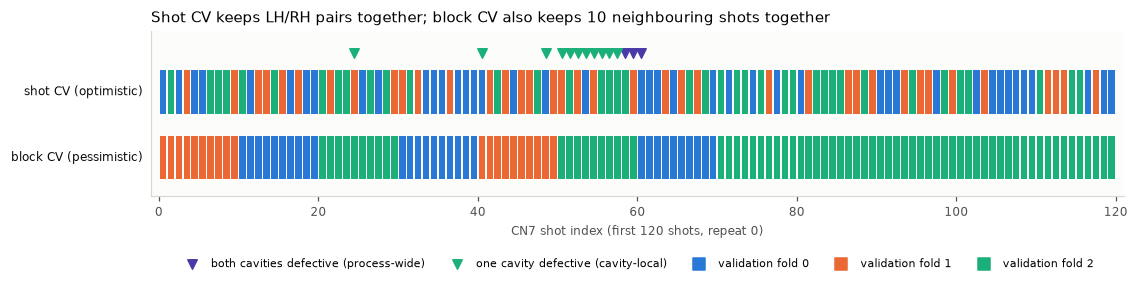

In [5]:
quick = json.loads(json.dumps(cfg))
quick["cv"]["n_repeats"] = 2          # 빨리 보려고 반복 2번만 (run_all.py 는 5번)
lab = data["labeled"]["cn7"].reset_index(drop=True)
fold_id = cv.fold_table(lab, quick)
same_fold = fold_id.groupby("shot_id")[["fold_shot_r0", "fold_block_r0"]].nunique().max()
print("쌍둥이가 서로 다른 묶음에 들어간 경우가 있나요?", "아니요 (안전)" if (same_fold == 1).all() else "예 (위험!)")
display(fold_id.head(6))
if (FIG / "key2_cv_concept.png").exists():
    display(Image(filename=str(FIG / "key2_cv_concept.png")))

## 5. 모델 한 번 돌려 보기

가장 단순한 모델 중 하나인 **로지스틱 회귀**(`logreg`)로 해 봅니다. 숫자 23개에 각각 '얼마나 중요한지' 무게를 곱해 더한 뒤,
그 합으로 **불량 의심 점수**를 내는 모델이에요.

금지 변수(행 번호, 정답, 상수 열, 짝 안의 순서 등)는 `check_feature_list` 가 자동으로 막아 줍니다.
점수로는 **PR-AUC**(불량을 위쪽에 잘 모았는지)와 **재현율@10%**(점수 상위 10%만 검사했을 때 불량을 몇 % 잡는지)를 봐요.

In [6]:
base, _ = features.select_base_features(data, feats, cfg["features"]["drop_constant"])
base = features.check_feature_list(base)
oofs, rows = [], []
for p in data["labeled"]:
    for mode in ("shot", "block"):
        o, m, _ = cv.run_cv(data["labeled"][p], base, ["logreg"], quick, p, mode, log=lambda *a: None)
        oofs.append(o)
        rows.append({"제품": p.upper(), "나누는 방법": mode, "shot PR-AUC": m.shot_ap.mean(),
                     "행 PR-AUC": m.row_ap.mean(), "재현율@10%": m["row_recall@10%"].mean(),
                     "무작위로 찍으면 PR-AUC": data["labeled"][p].y.mean()})
oof = pd.concat(oofs, ignore_index=True)
pd.DataFrame(rows).round(3)

,제품,나누는 방법,shot PR-AUC,행 PR-AUC,재현율@10%,무작위로 찍으면 PR-AUC
0,CN7,shot,0.351,0.392,0.706,0.014
1,CN7,block,0.194,0.253,0.471,0.014
2,RG3,shot,0.042,0.021,0.060,0.021
3,RG3,block,0.037,0.018,0.020,0.021


**읽는 법**: 같은 모델인데도 block CV 점수가 shot CV 보다 낮아요. 옆 shot 을 못 보게 막았더니 점수가 내려간 거예요.
그리고 RG3 는 '무작위로 찍으면' 값과 거의 같아요. 즉 **RG3 는 공정 숫자만으로는 불량을 알아채기 어렵다**는 뜻이에요.

## 6. 현장에서 쓰는 방법 — "위에서부터 몇 %만 검사할까?"

모든 제품을 다 검사할 수는 없으니, **점수가 높은 순서대로 일부만** 검사한다고 생각해 봐요.
무작위로 10%를 검사하면 불량도 10%쯤 잡혀요. 모델 순서대로 10%를 검사했을 때 그보다 많이 잡으면 모델이 도움이 되는 거예요.

In [7]:
rows = []
for (p, mode), g in oof.groupby(["product", "cv_mode"]):
    r = {"제품": p.upper(), "나누는 방법": mode}
    for b in (0.02, 0.05, 0.10):
        r[f"상위 {b:.0%} 검사 시 잡는 불량"] = sum(recall_at_budget(x.y, x.p, b) for _, x in g.groupby("repeat")) / g.repeat.nunique()
    rows.append(r)
display(pd.DataFrame(rows).round(2))
print("무작위 검사라면: 2% → 0.02, 5% → 0.05, 10% → 0.10")

,제품,나누는 방법,상위 2% 검사 시 잡는 불량,상위 5% 검사 시 잡는 불량,상위 10% 검사 시 잡는 불량
0,CN7,block,0.35,0.35,0.47
1,CN7,shot,0.44,0.53,0.71
2,RG3,block,0.00,0.00,0.02
3,RG3,shot,0.00,0.00,0.06


무작위 검사라면: 2% → 0.02, 5% → 0.05, 10% → 0.10


## 7. 어떤 불량을 잡고, 어떤 불량을 놓칠까?

불량에는 두 종류가 있어요.

- **쌍둥이 둘 다 불량**: 기계 설정(공정 조건) 자체가 흔들렸을 때 → 숫자에 흔적이 남아요.
- **한쪽만 불량**: 금형의 한 칸에만 문제가 있을 때 → 두 제품의 숫자가 똑같으니 **숫자로는 구분할 수 없어요.**

아래 표는 불량 종류별로 잡힌 행 수예요 (반복당 평균).

In [8]:
rows = []
for p in data["labeled"]:
    t, info = experiments.defect_type_detection(oof, {"dataset": p, "model": "logreg"}, p, shot_types(data["labeled"][p]))
    rows.append(t.assign(제품=p.upper()))
pd.concat(rows, ignore_index=True).round(1)

,cv_mode,defect_type,shots,defect_rows,TP rows top2%,TP rows top5%,TP rows top10%,TP rows score≥0.5,제품
0,block,cavity_local,11,11,0.0,0.0,2.0,0.0,CN7
1,block,process_wide,3,6,6.0,6.0,6.0,6.0,CN7
2,shot,cavity_local,11,11,1.5,3.0,6.0,4.0,CN7
3,shot,process_wide,3,6,6.0,6.0,6.0,6.0,CN7
4,block,cavity_local,25,25,0.0,0.0,0.5,4.5,RG3
5,shot,cavity_local,25,25,0.0,0.0,1.5,7.0,RG3


**읽는 법**: block CV(처음 보는 구간)에서 잡힌 것은 거의 **둘 다 불량** 쪽이에요. 한쪽만 불량은 잘 못 잡아요.
그래서 현장에는 이렇게 제안합니다: **공정 데이터 모델은 '기계 설정 이상' 찾기**에 쓰고,
**한 칸만 생기는 불량은 금형 점검이나 카메라(비전) 검사** 같은 다른 방법으로 찾자.

## 8. 몰래 답이 새는 구멍(누수) 찾기

쌍둥이 두 줄 중 **어느 줄이 먼저 기록됐는지**를 변수로 넣으면 점수가 올라가요. 그런데 이건 금형 칸(LH/RH)이 아니라
**기록 순서**였고, 불량인 줄이 먼저 기록되는 경우가 많았어요. 즉 **정답의 흔적이 새어 들어온 것**(누수)이에요.
정말 그런지 같은 방법으로 켰다 껐다 해 봅니다. (본 모델에는 절대 쓰지 않아요 — 비교용)

In [9]:
rows = []
for p in data["labeled"]:
    lab_a = features.add_pair_position(data["labeled"][p])
    for name, fs, allow in (("끔", base, set()), ("켬(누수)", base + ["pair_first"], features.LEAKY_ABLATION_FEATURES)):
        _, m, _ = cv.run_cv(lab_a, features.check_feature_list(fs, allow=allow), ["logreg"], quick, p, "shot",
                            log=lambda *a: None)
        rows.append({"제품": p.upper(), "짝 안 순서 변수": name, "행 ROC-AUC": m.row_roc_auc.mean(), "행 PR-AUC": m.row_ap.mean()})
pd.DataFrame(rows).round(3)

,제품,짝 안 순서 변수,행 ROC-AUC,행 PR-AUC
0,CN7,끔,0.922,0.392
1,CN7,켬(누수),0.936,0.450
2,RG3,끔,0.474,0.021
3,RG3,켬(누수),0.675,0.036


**읽는 법**: '켬' 쪽 점수가 올라가요. 하지만 이건 실력이 아니라 **정답을 살짝 본 점수**예요.
그래서 이 변수는 설정 파일에서 막아 두었고, 켜려고 하면 프로그램이 멈추도록 만들었어요.

## 9. 전체 결과 보기

위에서는 작게 돌렸어요. 모든 모델(8개) × 5번 반복의 결과, 오류 분석, 현장 활용 표는 `outputs/report.md` 에 있어요.
아래는 그 보고서의 **한 장 요약** 그림이에요 (없으면 `python run_all.py` 를 먼저 실행하세요).

## 0. 한 장 요약

- **문제**: 사출 공정값(표준화된 23개 변수)만으로 불량(PassOrFail=1)을 미리 찾아 검사 우선순위를 정한다. CN7 1,211행 중 불량 17행, RG3 1,182행 중 불량 25행.
- **대표 지표 = 검사비율별 재현율** ('점수 상위 k% 만 검사하면 불량을 몇 % 잡는가'). 처음 보는 생산 구간을 가정한 **block CV(비관)** ~ 같은 구간 안을 가정한 **shot CV(낙관)** 범위로 제시.

| 제품 | 모델 | 신호 | 재현율@2% (block~shot) | 재현율@5% (block~shot) | 재현율@10% (block~shot) | shot AP (block~shot) |
|---|---|---|---|---|---|---|
| CN7 | logreg | 있음 | 0.35 ~ 0.46 | 0.35 ~ 0.56 | 0.49 ~ 0.73 | 0.19 ~ 0.35 |
| RG3 | lgbm | 없음(기준선 수준) | 0.03 ~ 0.00 | 0.07 ~ 0.04 | 0.13 ~ 0.08 | 0.05 ~ 0.04 |
| 무작위 검사 | - | - | 0.02 | 0.05 | 0.10 | ≈불량률 |


**핵심 발견**

1. 공정값이 똑같은 두 행 = 한 번 사출(shot)의 LH/RH 두 제품. 짝 한쪽만 불량인 경우가 대부분이라 행 단위 성능에 넘을 수 없는 상한이 있음 → shot 단위로 묶어 나누고 평가 (1장)
2. 짝 안의 행 순서는 캐비티가 아니라 기록 순서이고 불량 여부와 얽혀 있음(누수) → 순서 변수를 쓰면 점수가 부풀려짐을 같은 분할로 확인하고 제외 (5장)
3. CN7 불량은 가동 초기 한 구간에 몰려 있어 이웃 shot 이 학습에 들어가면 과대평가 → 연속 10 shot 을 묶는 block CV 를 기준으로 모델을 고르고, shot CV 와 함께 범위로 보고 (2장)
4. 공정변수는 **shot 전체 이상(짝 둘 다 불량)은 잡지만 캐비티 국소 불량(한쪽만 불량)은 못 

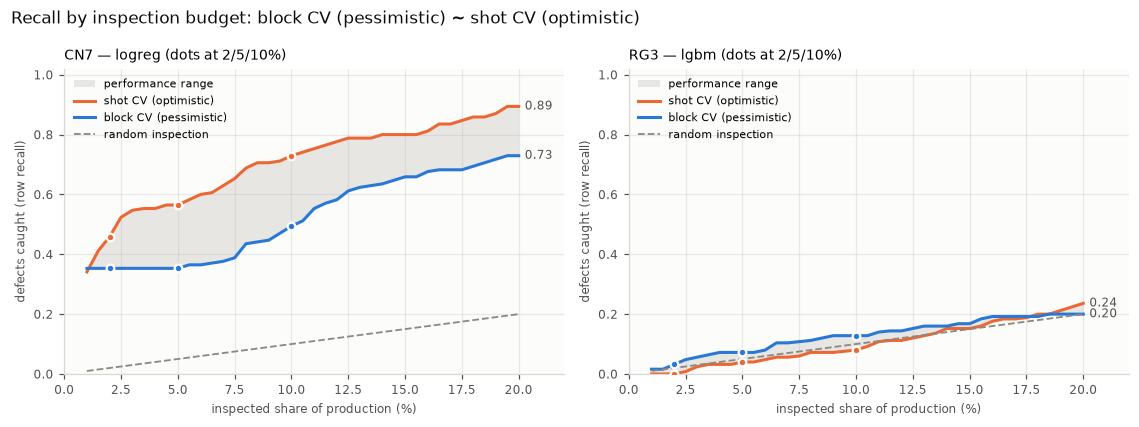

In [10]:
rep = ROOT / cfg["output_dir"] / ("synthetic/report.md" if SYNTHETIC else "report.md")
if rep.exists():
    text = rep.read_text(encoding="utf-8")
    start = text.find("## 0.")
    print(text[start:text.find("## 1.", start)][:2500])
if (FIG / "key3_recall_range.png").exists():
    display(Image(filename=str(FIG / "key3_recall_range.png")))

## 용어 사전

| 말 | 쉬운 뜻 |
|---|---|
| shot | 기계가 한 번 쏜 것. 제품이 2개(LH, RH) 나와요 |
| 표준화 | 숫자들을 평균 0, 흩어진 정도 1로 맞추는 것. 원래 단위(℃ 등)는 사라져요 |
| 교차검증 (CV) | 데이터를 나눠서 '공부용'과 '시험용'을 돌아가며 바꿔 보는 방법 |
| shot CV / block CV | 쌍둥이만 같이 두기(후한 점수) / 옆 10개 shot 까지 같이 두기(짠 점수) |
| PR-AUC | 불량을 점수 위쪽에 얼마나 잘 모았는지. 무작위면 불량 비율(약 0.01~0.02)과 같아요 |
| 재현율@10% | 점수 상위 10%만 검사할 때 전체 불량 중 몇 %를 잡는지 |
| 누수 | 모델이 정답의 흔적을 몰래 보고 점수가 부풀려지는 것 |
| 행 단위 천장 | 쌍둥이 숫자가 똑같아서 생기는, 넘을 수 없는 점수 한계 |